Training Random Forest Classifier...
Training 1D CNN from Scratch...
Training Transfer Learning CNN Model...

                             BREAST CANCER DATASET - PERFORMANCE METRICS SUMMARY                              
Model Name                             | Accuracy     | Precision    | Recall       | Macro F1    
--------------------------------------------------------------------------------------------------------------
Random Forest Classifier               |  95.61%       |  95.51%       |  95.04%       |  95.26%
1D CNN (From Scratch)                  |  93.86%       |  94.10%       |  92.66%       |  93.30%
Transfer Learning CNN (Frozen Base)    |  91.23%       |  90.58%       |  90.58%       |  90.58%


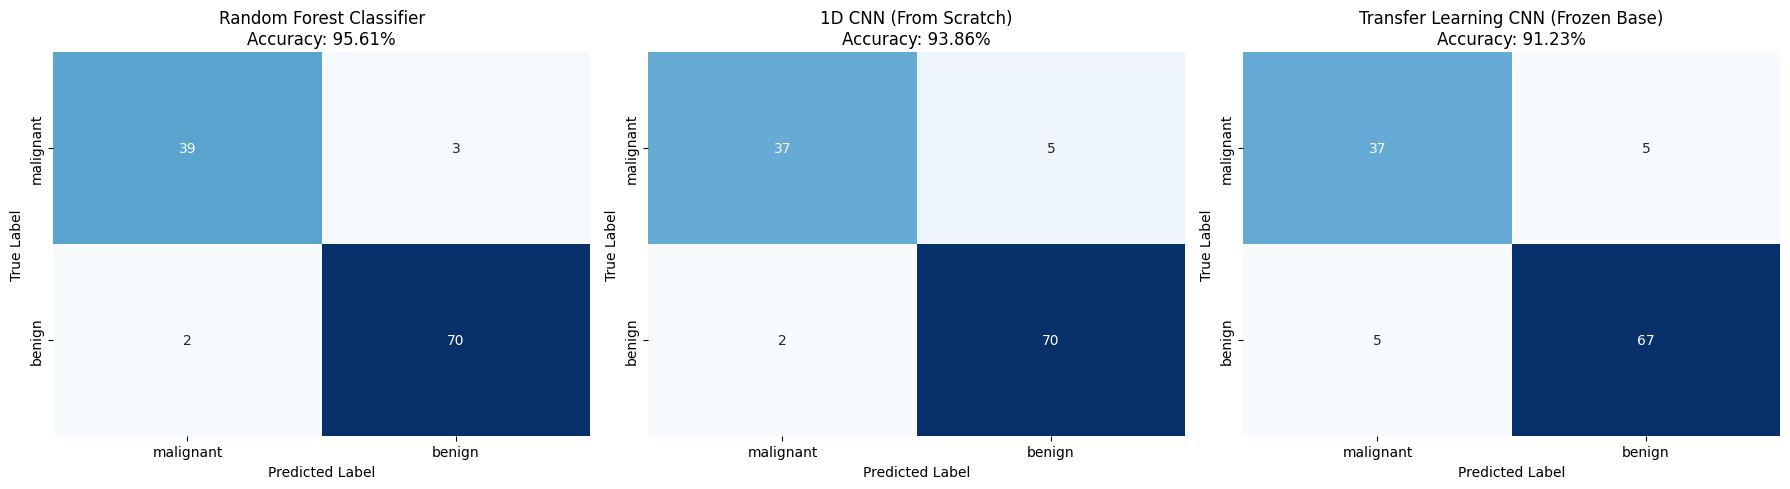

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# 1. Load and Preprocess Breast Cancer Dataset (30 features, Binary Classification)
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

evaluation_results = []

# ==========================================
# MODEL 1: Random Forest Classifier
# ==========================================
print("Training Random Forest Classifier...")
rf_model = RandomForestClassifier(n_estimators=150, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

evaluation_results.append({
    "Model": "Random Forest Classifier",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, average='macro'),
    "Recall": recall_score(y_test, rf_pred, average='macro'),
    "Macro F1": f1_score(y_test, rf_pred, average='macro'),
    "Confusion Matrix": confusion_matrix(y_test, rf_pred)
})


# ==========================================
# PREPARE DATA FOR PYTORCH (CNN & Transfer Learning)
# Reshape 30 features into 1D sequence format: (Batch, Channels=1, Length=30)
# ==========================================
X_train_t = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True)


# ==========================================
# MODEL 2 & 3 ARCHITECTURE: 1D CNN Base (Binary Classification)
# ==========================================
class Tabular1DCNNClassifier(nn.Module):
    def __init__(self):
        super(Tabular1DCNNClassifier, self).__init__()
        self.conv_block = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1) # Reduces sequence length to 1
        )
        self.fc_block = nn.Sequential(
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid() # Outputs probability between 0 and 1
        )

    def forward(self, x):
        x = self.conv_block(x)
        x = x.view(x.size(0), -1) # Flatten
        x = self.fc_block(x)
        return x


# ==========================================
# MODEL 2: 1D CNN (Trained from Scratch)
# ==========================================
print("Training 1D CNN from Scratch...")
cnn_model = Tabular1DCNNClassifier()
criterion = nn.BCELoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.005)

cnn_model.train()
for epoch in range(40):
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = cnn_model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

cnn_model.eval()
with torch.no_grad():
    cnn_probs = cnn_model(X_test_t).squeeze().numpy()
    cnn_pred = (cnn_probs >= 0.5).astype(int)

evaluation_results.append({
    "Model": "1D CNN (From Scratch)",
    "Accuracy": accuracy_score(y_test, cnn_pred),
    "Precision": precision_score(y_test, cnn_pred, average='macro'),
    "Recall": recall_score(y_test, cnn_pred, average='macro'),
    "Macro F1": f1_score(y_test, cnn_pred, average='macro'),
    "Confusion Matrix": confusion_matrix(y_test, cnn_pred)
})


# ==========================================
# MODEL 3: Transfer Learning (TL) 1D CNN
# Strategy: Freeze early convolutional feature extractor
# and fine-tune only the dense classification head.
# ==========================================
print("Training Transfer Learning CNN Model...")
tl_model = Tabular1DCNNClassifier()

# Freeze convolutional feature layers
for param in tl_model.conv_block.parameters():
    param.requires_grad = False

# Optimize only the classification head
optimizer_tl = optim.Adam(tl_model.fc_block.parameters(), lr=0.005)

tl_model.train()
for epoch in range(40):
    for batch_x, batch_y in train_loader:
        optimizer_tl.zero_grad()
        outputs = tl_model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer_tl.step()

tl_model.eval()
with torch.no_grad():
    tl_probs = tl_model(X_test_t).squeeze().numpy()
    tl_pred = (tl_probs >= 0.5).astype(int)

evaluation_results.append({
    "Model": "Transfer Learning CNN (Frozen Base)",
    "Accuracy": accuracy_score(y_test, tl_pred),
    "Precision": precision_score(y_test, tl_pred, average='macro'),
    "Recall": recall_score(y_test, tl_pred, average='macro'),
    "Macro F1": f1_score(y_test, tl_pred, average='macro'),
    "Confusion Matrix": confusion_matrix(y_test, tl_pred)
})


# ==========================================
# PERFORMANCE SUMMARY TABLE DISPLAY
# ==========================================
print("\n" + "=" * 110)
print(f"{'BREAST CANCER DATASET - PERFORMANCE METRICS SUMMARY':^110}")
print("=" * 110)
print(f"{'Model Name':<38} | {'Accuracy':<12} | {'Precision':<12} | {'Recall':<12} | {'Macro F1':<12}")
print("-" * 110)

for res in evaluation_results:
    print(
        f"{res['Model']:<38} | "
        f"{res['Accuracy']*100:6.2f}%       | "
        f"{res['Precision']*100:6.2f}%       | "
        f"{res['Recall']*100:6.2f}%       | "
        f"{res['Macro F1']*100:6.2f}%"
    )
print("=" * 110)


# ==========================================
# VISUALIZATION: Confusion Matrix Heatmaps
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.ravel()

for idx, res in enumerate(evaluation_results):
    sns.heatmap(
        res['Confusion Matrix'],
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[idx],
        cbar=False,
        xticklabels=cancer.target_names,
        yticklabels=cancer.target_names
    )
    axes[idx].set_title(f"{res['Model']}\nAccuracy: {res['Accuracy']*100:.2f}%")
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

plt.tight_layout()
plt.show()